# MCS-201 Hardware Acceleration
**Artificial Intelligence and System Engineering · Prince of Songkla University, Phuket Campus**

---

# Lab 5 — Profile, Then Optimise
### CUDA libraries (cuBLAS, CuPy), Nsight Systems และ Nsight Compute

| | |
|---|---|
| **สัปดาห์** | 6 |
| **วันปฏิบัติการ** | จันทร์ 14 ก.ย. 2569 |
| **กำหนดส่ง** | จันทร์ 14 ก.ย. 2569 **ภายใน 13.00 น.** (วันเดียวกับคาบปฏิบัติการ) |
| **น้ำหนัก** | อยู่ในหมวด Lab ซึ่งคิดเป็น 15% ของคะแนนรายวิชา (ทุกแลปถ่วงน้ำหนักเท่ากัน) |
| **ช่องทางส่ง** | LMS — lms.psu.ac.th |
| **ไฟล์ที่ต้องส่ง** | `Lab5_<รหัสนักศึกษา>.ipynb` พร้อมไฟล์ `.cu` และ `.csv` จาก ncu (บีบเป็น .zip) |
| **ผู้สอน** | ผศ.ดร.ฐิตินันท์ เกลี้ยงสุวรรณ · thitinan.kl@phuket.psu.ac.th · ห้อง 6714 |

> **ต้องใช้ผลจาก Lab 4** ส่วนที่ 1 เทียบ cuBLAS กับ `tiled32` และส่วนที่ 3 นำ kernel จาก Lab 3–4
> มาวัดด้วย Nsight Compute

## 1. วัตถุประสงค์ (Objectives)

1. เรียกใช้ cuBLAS ได้ถูกต้องกับข้อมูลแบบ row-major และวัดว่าไลบรารีเร็วกว่า kernel ที่เขียนเองเท่าใด — *CLO2*
2. ใช้ **Nsight Systems** อ่าน timeline ของทั้งโปรแกรม หาว่าเวลาหายไปที่ใด แล้วแก้ที่ต้นเหตุ — *CLO3*
3. ใช้ **Nsight Compute** อ่านค่า Speed of Light, occupancy, sectors/request และ bank conflict
   แล้วเชื่อมตัวเลขเข้ากับสาเหตุที่เรียนมาในสัปดาห์ที่ 5 — *CLO2, CLO3*
4. ปรับแต่ง kernel ตามขั้นตอน **วัด → profile → ตั้งสมมติฐาน → แก้ทีละอย่าง → วัดซ้ำ** พร้อมบันทึกหลักฐาน — *CLO3*

## 2. การเตรียมสภาพแวดล้อมบน Google Colab

รูปแบบเดียวกับ Lab 3–4 (`%%writefile` แล้วคอมไพล์ด้วย `nvcc`) แต่วันนี้ต้องมี profiler สองตัวเพิ่ม
เซลล์ถัดไปจะค้นหา `nsys` และ `ncu` ในเครื่อง ถ้าไม่พบจะติดตั้งรุ่นที่ตรงกับ CUDA Toolkit ให้อัตโนมัติ (1–3 นาที)

> **สำคัญ** Colab ไม่มีหน้าจอ GUI ของ Nsight ในแลปนี้เราอ่านผลเป็นตาราง (`--stats`, `--csv`) และวาด timeline
> เองด้วย matplotlib ถ้าต้องการดูใน GUI ให้ดาวน์โหลดไฟล์ `.nsys-rep` / `.ncu-rep` ไปเปิดในเครื่องตนเอง (ติดตั้งฟรี)

In [1]:
!nvcc --version | tail -2
!nvidia-smi --query-gpu=name,compute_cap,memory.total,driver_version --format=csv

Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
name, compute_cap, memory.total [MiB], driver_version
Tesla T4, 7.5, 15360 MiB, 580.82.07


In [2]:
import subprocess
cap = subprocess.check_output(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"], text=True).splitlines()[0].strip()
ARCH = "sm_" + cap.replace(".", "")      # TODO: แก้ให้ตรงกับ GPU ของท่าน
                    # sm_75 = T4 · sm_80 = A100 · sm_89 = L4 · sm_90 = H100

# TODO: กรอกค่าจาก Lab 4 ของท่านเอง
TILED32_N2048_MS = 16.978      # เวลา (ms) ของ tiled32 ที่ N = 2048 (Lab 4 ตารางที่ 1 แถว 2)
print("using", ARCH, "· tiled32 (Lab 4) =", TILED32_N2048_MS, "ms")

using sm_75 · tiled32 (Lab 4) = 16.978 ms


In [3]:
# ---- ค้นหา / ติดตั้ง Nsight Systems (nsys) และ Nsight Compute (ncu) -----------------
import os, re, glob, shutil, subprocess

PATTERNS = {
    "nsys": ["/usr/local/cuda*/bin/nsys", "/opt/nvidia/nsight-systems/*/bin/nsys",
             "/usr/local/cuda*/nsight-systems-*/bin/nsys"],
    "ncu":  ["/usr/local/cuda*/bin/ncu", "/opt/nvidia/nsight-compute/*/ncu",
             "/usr/local/cuda*/nsight-compute-*/ncu"],
}
def find_tool(name):
    p = shutil.which(name)
    if p: return p
    c = sorted(sum([glob.glob(pat) for pat in PATTERNS[name]], []))
    return c[-1] if c else None

def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True).returncode == 0

def apt_install(pkg):
    if sh(f"apt-get install -y -qq {pkg}"): return True
    if sh(f"apt-get update -qq && apt-get install -y -qq {pkg}"): return True
    dist = subprocess.run("lsb_release -rs", shell=True, capture_output=True,
                          text=True).stdout.strip().replace(".", "")
    sh("wget -q https://developer.download.nvidia.com/compute/cuda/repos/"
       f"ubuntu{dist}/x86_64/cuda-keyring_1.1-1_all.deb -O /tmp/kr.deb && dpkg -i /tmp/kr.deb")
    return sh(f"apt-get update -qq && apt-get install -y -qq {pkg}")

v = re.search(r"release (\d+)\.(\d+)",
              subprocess.run(["nvcc", "--version"], capture_output=True, text=True).stdout)
cuda_mm = f"{v.group(1)}-{v.group(2)}"                       # เช่น 12-5
for tool, pkg in [("nsys", f"cuda-nsight-systems-{cuda_mm}"),
                  ("ncu",  f"cuda-nsight-compute-{cuda_mm}")]:
    p = find_tool(tool)
    if p is None:
        print(f"ไม่พบ {tool} — กำลังติดตั้ง {pkg} ...")
        apt_install(pkg)
        p = find_tool(tool)
    if p:
        d = os.path.dirname(p)
        if d not in os.environ["PATH"].split(":"):
            os.environ["PATH"] = d + ":" + os.environ["PATH"]
        print(f"{tool:5s} พร้อมใช้: {p}")
    else:
        print(f"{tool:5s} ติดตั้งไม่สำเร็จ — แจ้งผู้สอนทันที")

nsys  พร้อมใช้: /usr/local/bin/nsys
ncu   พร้อมใช้: /usr/local/cuda/bin/ncu


In [4]:
!nsys --version
!ncu --version | tail -1

NVIDIA Nsight Systems version 2025.3.1.0
Version 2025.3.1.0 (build 36398880) (public-release)


In [5]:
# ---- ฟังก์ชันช่วยอ่านผล (รันเซลล์นี้ครั้งเดียว ไม่ต้องแก้) ----
import io, glob, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def _read_quoted_csv(path):
    """อ่านเฉพาะบรรทัด CSV (ขึ้นต้นด้วย ") ข้ามข้อความ ==PROF== และ printf ของโปรแกรม"""
    lines = [l for l in open(path, encoding="utf-8", errors="ignore") if l.startswith('"')]
    return pd.read_csv(io.StringIO("".join(lines)))

def ncu_table(path):
    """แปลงไฟล์ CSV จาก ncu --csv --metrics ... ให้เป็นตาราง kernel x metric"""
    df = _read_quoted_csv(path)
    df["Kernel"] = df["Kernel Name"].astype(str).str.split("(").str[0]
    df["Value"] = pd.to_numeric(df["Metric Value"].astype(str).str.replace(",", ""),
                                errors="coerce")
    order = list(dict.fromkeys(df["Kernel"]))
    t = df.pivot_table(index="Kernel", columns="Metric Name", values="Value", aggfunc="first")
    return t.reindex(order)

def ncu_summary(path):
    """ตารางสรุปที่อ่านง่าย พร้อมคอลัมน์ที่คำนวณเพิ่ม"""
    t = ncu_table(path)
    g = lambda m: t[m] if m in t.columns else float("nan")
    out = pd.DataFrame(index=t.index)
    out["time (us)"]           = g("gpu__time_duration.sum") / 1e3
    out["Compute SOL %"]       = g("sm__throughput.avg.pct_of_peak_sustained_elapsed")
    out["Memory SOL %"]        = g("gpu__compute_memory_throughput.avg.pct_of_peak_sustained_elapsed")
    out["DRAM %"]              = g("dram__throughput.avg.pct_of_peak_sustained_elapsed")
    out["occ. achieved %"]     = g("sm__warps_active.avg.pct_of_peak_sustained_active")
    out["occ. theoretical %"]  = g("sm__maximum_warps_per_active_cycle_pct")
    out["sectors / request"]   = (g("l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum")
                                  / g("l1tex__t_requests_pipe_lsu_mem_global_op_ld.sum"))
    out["smem wavefronts / ld"] = (g("l1tex__data_pipe_lsu_wavefronts_mem_shared_op_ld.sum")
                                   / g("smsp__inst_executed_op_shared_ld.sum"))
    out["smem ld conflicts"]   = g("l1tex__data_bank_conflicts_pipe_lsu_mem_shared_op_ld.sum")
    out["L1 hit %"]            = g("l1tex__t_sector_hit_rate.pct")
    return out.dropna(axis=1, how="all").round(2)

def _col(df, prefix):
    return next(c for c in df.columns if c.startswith(prefix))

def nsys_timeline(rep, title=None, t_max_ms=None):
    """วาด timeline อย่างง่ายจากไฟล์ .nsys-rep (ใช้แทน GUI ของ Nsight Systems บน Colab)"""
    pre = rep.replace(".nsys-rep", "") + "_tl"
    for r in ["cuda_gpu_trace", "nvtx_pushpop_trace"]:
        subprocess.run(["nsys", "stats", "-q", "-r", r, "-f", "csv", "-o", pre,
                        "--force-overwrite", "true", "--force-export", "true", rep],
                       capture_output=True, text=True)
    gpu = pd.read_csv(glob.glob(f"{pre}*cuda_gpu_trace*.csv")[0])
    nv  = pd.read_csv(glob.glob(f"{pre}*nvtx_pushpop_trace*.csv")[0])
    gs, gd, gn = _col(gpu, "Start"), _col(gpu, "Duration"), _col(gpu, "Name")
    ns, nd, nn = _col(nv, "Start"), _col(nv, "Duration"), _col(nv, "Name")
    frames = nv[nv[nn] == "frame"]
    t0 = frames[ns].min() if len(frames) else gpu[gs].min()

    def kind(name):
        n = str(name)
        if "memcpy" in n and ("HtoD" in n or "Host-to-Device" in n): return "GPU: copy H2D"
        if "memcpy" in n and ("DtoH" in n or "Device-to-Host" in n): return "GPU: copy D2H"
        if "memset" in n or "memcpy" in n: return None
        return "GPU: kernels"
    rows = ["CPU: fill", "CPU: checksum", "GPU: copy H2D", "GPU: kernels", "GPU: copy D2H"]
    color = {"CPU: fill": "#D9822B", "CPU: checksum": "#D4A72C", "GPU: copy H2D": "#C7566B",
             "GPU: kernels": "#6E5AE6", "GPU: copy D2H": "#10A5A0"}
    bars = {r: [] for r in rows}
    for _, e in nv.iterrows():
        r = {"cpu: fill": "CPU: fill", "cpu: checksum": "CPU: checksum"}.get(e[nn])
        if r: bars[r].append(((e[ns] - t0) / 1e6, e[nd] / 1e6))
    for _, e in gpu.iterrows():
        r = kind(e[gn])
        if r and e[gs] >= t0: bars[r].append(((e[gs] - t0) / 1e6, e[gd] / 1e6))

    fig, ax = plt.subplots(figsize=(14, 3.6))
    for i, r in enumerate(rows):
        ax.broken_barh(bars[r], (len(rows) - 1 - i - 0.35, 0.7), color=color[r])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows[::-1])
    ax.set_xlabel("time (ms) from the first frame")
    if t_max_ms: ax.set_xlim(0, t_max_ms)
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(title or rep)
    plt.tight_layout(); plt.show()
    busy = {r: sum(d for _, d in bars[r]) for r in rows}
    return pd.Series(busy, name="busy time (ms)").round(2)

---
## 3. ขั้นตอนการปฏิบัติ

### ส่วนที่ 1 — Libraries first: cuBLAS เทียบกับ kernel ของท่าน

โปรแกรม `gemm_lib.cu` มี `tiled32` จากเฉลย Lab 4 และฟังก์ชัน `gemmCublas` ที่เรียก `cublasSgemm`
ข้อมูลเป็นค่าสุ่มในช่วง [-1, 1] และตรวจความถูกต้องกับ CPU แบบสุ่ม 256 ตำแหน่ง

**กับดักที่ต้องเจอก่อน** cuBLAS สืบทอดมาจาก BLAS ของ Fortran จึงมองหน่วยความจำเป็น **column-major**
ส่วนอาร์เรย์ของ C/C++ เป็น **row-major** เรียกแบบตรงไปตรงมาจะได้ผลลัพธ์ผิด (แต่ไม่มี error)

1. รันเซลล์ถัดไปทั้งที่ยังไม่แก้ — ดูว่า cuBLAS ขึ้น `[ไม่ผ่าน]`
2. แก้ **TODO (1)** โดยเปลี่ยนเฉพาะลำดับของเมทริกซ์ที่ส่งเข้า `cublasSgemm` แล้วรันใหม่จนได้ `[ผ่าน]`

In [6]:
%%writefile gemm_lib.cu
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <chrono>
#include <cublas_v2.h>

#define CUDA_CHECK(call)                                        \
  do {                                                          \
    cudaError_t err = (call);                                   \
    if (err != cudaSuccess) {                                   \
      fprintf(stderr, "CUDA %s:%d: %s\n", __FILE__, __LINE__,   \
              cudaGetErrorString(err));                         \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

#define CUBLAS_CHECK(call)                                      \
  do {                                                          \
    cublasStatus_t st = (call);                                 \
    if (st != CUBLAS_STATUS_SUCCESS) {                          \
      fprintf(stderr, "cuBLAS %s:%d: status %d\n",              \
              __FILE__, __LINE__, (int)st);                     \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

#define T 32

/* ---- tiled matmul T = 32 จากเฉลย Lab 4 (ให้มาแล้ว ห้ามแก้) ------------ */
__global__ void tiled32(int N, const float *A, const float *B, float *C) {
    __shared__ float As[T][T], Bs[T][T];
    int tx = threadIdx.x, ty = threadIdx.y;
    int row = blockIdx.y*T + ty, col = blockIdx.x*T + tx;
    float sum = 0.0f;
    for (int t = 0; t < N/T; t++) {
        As[ty][tx] = A[row*N + (t*T + tx)];
        Bs[ty][tx] = B[(t*T + ty)*N + col];
        __syncthreads();
        for (int k = 0; k < T; k++) sum += As[ty][k] * Bs[k][tx];
        __syncthreads();
    }
    C[row*N + col] = sum;
}

/* ---- cuBLAS: C = A * B โดยที่ A, B, C เก็บแบบ row-major ---------------- */
static void gemmCublas(cublasHandle_t h, int N,
                       const float *A, const float *B, float *C) {
    const float alpha = 1.0f, beta = 0.0f;
    /* TODO (1): บรรทัดด้านล่างเขียนแบบ "ตรงไปตรงมา" คือส่ง A ก่อน B
       รันแล้วจะได้ [ไม่ผ่าน] เพราะ cuBLAS มองหน่วยความจำเป็น column-major
       ให้แก้เฉพาะลำดับของ matrix ที่ส่งเข้าไป โดยห้าม transpose ข้อมูลและห้ามใช้ CUBLAS_OP_T
       (คำใบ้: หน่วยความจำของ A แบบ row-major = A^T แบบ column-major และ (AB)^T = B^T A^T)  */
    CUBLAS_CHECK(cublasSgemm(h, CUBLAS_OP_N, CUBLAS_OP_N,
                             N, N, N,
                             &alpha,
                             B, N,        /* TODO (1) เมทริกซ์ตัวแรก   */
                             A, N,        /* TODO (1) เมทริกซ์ตัวที่สอง */
                             &beta,
                             C, N));
}

/* ---- ตรวจความถูกต้องแบบสุ่ม 256 ตำแหน่ง เทียบกับ CPU (double) ------------ */
static bool check(int N, const float *A, const float *B, const float *C) {
    srand(7);
    for (int s = 0; s < 256; s++) {
        int i = rand() % N, j = rand() % N;
        double ref = 0.0, mag = 0.0;
        for (int k = 0; k < N; k++) {
            ref += (double)A[i*N + k] * B[k*N + j];
            mag += fabs((double)A[i*N + k] * B[k*N + j]);
        }
        if (fabs(C[i*N + j] - ref) > 1e-4 * mag + 1e-5) {
            printf("    ผิดที่ C[%d][%d]: ได้ %.5f ควรได้ %.5f\n", i, j, C[i*N + j], ref);
            return false;
        }
    }
    return true;
}

int main(int argc, char **argv) {
    int N = (argc > 1) ? atoi(argv[1]) : 2048;          /* ต้องหารด้วย 32 ลงตัว */
    size_t bytes = (size_t)N * N * sizeof(float);
    float *hA = (float*)malloc(bytes), *hB = (float*)malloc(bytes),
          *hC = (float*)malloc(bytes);
    srand(1);
    for (int i = 0; i < N*N; i++) {
        hA[i] = 2.0f * rand() / RAND_MAX - 1.0f;
        hB[i] = 2.0f * rand() / RAND_MAX - 1.0f;
    }
    float *dA, *dB, *dC;
    CUDA_CHECK(cudaMalloc(&dA, bytes)); CUDA_CHECK(cudaMalloc(&dB, bytes));
    CUDA_CHECK(cudaMalloc(&dC, bytes));
    CUDA_CHECK(cudaMemcpy(dA, hA, bytes, cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(dB, hB, bytes, cudaMemcpyHostToDevice));

    /* สร้าง handle ครั้งเดียว — จับเวลาไว้ให้เห็นว่าแพงแค่ไหน */
    auto h0 = std::chrono::steady_clock::now();
    cublasHandle_t handle;
    CUBLAS_CHECK(cublasCreate(&handle));
    auto h1 = std::chrono::steady_clock::now();
    double createMs = std::chrono::duration<double, std::milli>(h1 - h0).count();

    cudaEvent_t s, e;
    CUDA_CHECK(cudaEventCreate(&s)); CUDA_CHECK(cudaEventCreate(&e));
    const int REPS = 10;
    double gflop = 2.0 * N * N * N / 1e9;
    float ms[2];
    const char *name[2] = {"tiled32 (Lab 4)", "cuBLAS SGEMM   "};

    for (int w = 0; w < 2; w++) {
        CUDA_CHECK(cudaMemset(dC, 0, bytes));
        for (int r = 0; r <= REPS; r++) {
            if (r == 1) CUDA_CHECK(cudaEventRecord(s));       /* r = 0 คือ warm-up */
            if (w == 0) tiled32<<<dim3(N/T, N/T), dim3(T, T)>>>(N, dA, dB, dC);
            else        gemmCublas(handle, N, dA, dB, dC);
        }
        CUDA_CHECK(cudaEventRecord(e));
        CUDA_CHECK(cudaEventSynchronize(e));
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaEventElapsedTime(&ms[w], s, e));
        ms[w] /= REPS;
        CUDA_CHECK(cudaMemcpy(hC, dC, bytes, cudaMemcpyDeviceToHost));
        bool ok = check(N, hA, hB, hC);
        printf("  %s : %8.3f ms   %6.3f TFLOPS   %s\n",
               name[w], ms[w], gflop / ms[w], ok ? "[ผ่าน]" : "[ไม่ผ่าน]");
    }
    printf("  cuBLAS เร็วกว่า tiled32 = %.2f เท่า   (N = %d)\n", ms[0] / ms[1], N);
    printf("  เวลาสร้าง cublasHandle = %.1f ms (ครั้งเดียวต่อโปรแกรม)\n", createMs);

    CUBLAS_CHECK(cublasDestroy(handle));
    CUDA_CHECK(cudaEventDestroy(s)); CUDA_CHECK(cudaEventDestroy(e));
    free(hA); free(hB); free(hC);
    CUDA_CHECK(cudaFree(dA)); CUDA_CHECK(cudaFree(dB)); CUDA_CHECK(cudaFree(dC));
    return 0;
}

Writing gemm_lib.cu


In [7]:
!nvcc -O3 -arch={ARCH} gemm_lib.cu -lcublas -o gemm_lib
!./gemm_lib 2048
!./gemm_lib 4096

  tiled32 (Lab 4) :   28.074 ms    0.612 TFLOPS   [ผ่าน]
  cuBLAS SGEMM    :    2.429 ms    7.074 TFLOPS   [ผ่าน]
  cuBLAS เร็วกว่า tiled32 = 11.56 เท่า   (N = 2048)
  เวลาสร้าง cublasHandle = 17.9 ms (ครั้งเดียวต่อโปรแกรม)
  tiled32 (Lab 4) :  146.079 ms    0.941 TFLOPS   [ผ่าน]
  cuBLAS SGEMM    :   30.945 ms    4.441 TFLOPS   [ผ่าน]
  cuBLAS เร็วกว่า tiled32 = 4.72 เท่า   (N = 4096)
  เวลาสร้าง cublasHandle = 3.1 ms (ครั้งเดียวต่อโปรแกรม)


**1.2 ไลบรารีเดียวกัน ผ่านประตู Python — CuPy**

CuPy ใช้ API แบบ NumPy แต่ `a @ b` ของ CuPy เรียก cuBLAS อยู่ข้างใต้ ตัวเลขจึงควรใกล้กับข้อ 1.1
เซลล์นี้จับเวลาสามแบบ: NumPy บน CPU, CuPy แบบ **ผิด** (ไม่ sync) และ CuPy แบบถูก (CUDA events)

In [8]:
import time, numpy as np, cupy as cp

N = 2048
a_h = np.random.uniform(-1, 1, (N, N)).astype(np.float32)
b_h = np.random.uniform(-1, 1, (N, N)).astype(np.float32)
a, b = cp.asarray(a_h), cp.asarray(b_h)
gflop = 2 * N**3 / 1e9

# (1) NumPy บน CPU
t = time.perf_counter(); c_h = a_h @ b_h; t_cpu = (time.perf_counter() - t) * 1e3

# (2) CuPy — จับเวลาแบบผิด: kernel ยังไม่เสร็จ แต่ Python คืนค่ามาแล้ว
c = a @ b; cp.cuda.Device().synchronize()                 # warm-up
t = time.perf_counter(); c = a @ b; t_wrong = (time.perf_counter() - t) * 1e3

# (3) CuPy — จับเวลาแบบถูก: CUDA events + รอให้ event เสร็จ
s, e = cp.cuda.Event(), cp.cuda.Event()
s.record()
for _ in range(10): c = a @ b
e.record(); e.synchronize()
t_gpu = cp.cuda.get_elapsed_time(s, e) / 10

err = float(np.max(np.abs(cp.asnumpy(c) - c_h)))
print(f"NumPy (CPU)            : {t_cpu:9.3f} ms   {gflop / t_cpu:7.3f} TFLOPS")
print(f"CuPy ไม่ sync (ผิด)      : {t_wrong:9.3f} ms   <- ตัวเลขนี้ไม่มีความหมาย")
print(f"CuPy + CUDA events     : {t_gpu:9.3f} ms   {gflop / t_gpu:7.3f} TFLOPS")
print(f"ผลต่างสูงสุด CPU vs GPU : {err:.2e}")

NumPy (CPU)            :   207.140 ms     0.083 TFLOPS
CuPy ไม่ sync (ผิด)      :     0.640 ms   <- ตัวเลขนี้ไม่มีความหมาย
CuPy + CUDA events     :     3.576 ms     4.804 TFLOPS
ผลต่างสูงสุด CPU vs GPU : 9.54e-05


**บันทึกผลและตอบคำถาม**

(ก) cuBLAS เร็วกว่า `tiled32` กี่เท่าที่ N = 2048 และที่ N = 4096 อัตราส่วนเปลี่ยนไปอย่างไร

_ตอบ:_ ที่ N=2048 ได้ 11.56 เท่า และ N=4096 ได้ 4.72 เท่า อัตราส่วนลดลงเมื่อ N เพิ่ม

(ข) ตัวเลข "CuPy ไม่ sync" เร็วเกินจริงไปกี่เท่า อธิบายด้วยคำว่า *asynchronous launch*
และบอกว่าตัวเลข CuPy แบบถูกต้องใกล้กับ cuBLAS ในข้อ 1.1 หรือไม่ เพราะอะไร

_ตอบ:_ แบบไม่ sync ดูเร็วเกินจริง 5.59 เท่า เพราะ asynchronous launch ทำให้ Python วัดแค่เวลาส่งงาน ส่วน events วัดจน GPU ทำเสร็จ ได้ 3.576 ms ใกล้ cuBLAS 2.429 ms แต่มี overhead ของ CuPy ด้วย

(ค) เวลาสร้าง `cublasHandle` ที่วัดได้คือเท่าใด ถ้าโปรแกรมเรียก `cublasCreate` ทุกครั้งก่อนคูณเมทริกซ์ 100 ครั้ง
ที่ N = 512 จะเกิดอะไรขึ้น

_ตอบ:_ ครั้งแรกสร้าง handle ใช้ 17.9 ms ถ้าสร้างใหม่ 100 ครั้งจะเสียราว 1,790 ms ควรสร้างครั้งเดียวแล้วใช้ซ้ำ

---
### ส่วนที่ 2 — Nsight Systems: เวลาของ "ทั้งโปรแกรม" หายไปที่ไหน

`app.cu` ประมวลผลภาพ 16 เฟรม (เฟรมละ 16 MB) ต่อเฟรมทำ: สร้างข้อมูลบน CPU → คัดลอกขึ้น GPU →
kernel 2 ตัว → คัดลอกกลับ → ตรวจ checksum บน CPU โปรแกรม **ถูกต้อง** แต่เขียนตามสัญชาตญาณ

โค้ดมีช่วง **NVTX** (`nvtxRangePushA` / `nvtxRangePop`) กำกับงานฝั่ง CPU ไว้แล้ว ช่วงเหล่านี้จะปรากฏบน timeline
ทำให้เห็นว่า CPU กำลังทำอะไรอยู่ในช่วงที่ GPU ว่าง

> **ห้ามแก้ `app.cu`** — นี่คือ baseline ของส่วนนี้

In [9]:
%%writefile app.cu
/* app.cu — โปรแกรมประมวลผล "เฟรม" แบบที่เขียนตามสัญชาตญาณ (ถูกต้อง แต่ช้า)
   ห้ามแก้ไฟล์นี้ — ใช้เป็น baseline สำหรับ Nsight Systems                  */
#include <cstdio>
#include <cstdlib>
#include <chrono>
#include <nvtx3/nvToolsExt.h>

#define CUDA_CHECK(call)                                        \
  do {                                                          \
    cudaError_t err = (call);                                   \
    if (err != cudaSuccess) {                                   \
      fprintf(stderr, "CUDA %s:%d: %s\n", __FILE__, __LINE__,   \
              cudaGetErrorString(err));                         \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

const int FRAMES = 16;
const int NPIX   = 1 << 22;                 /* 4M float = 16 MB ต่อเฟรม */

__global__ void normalize(int n, const float *in, float *out, float mean, float inv) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < n) out[i] = (in[i] - mean) * inv;
}
__global__ void gammaClamp(int n, float *x, float g) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < n) x[i] = powf(fminf(fmaxf(x[i], 0.0f), 1.0f), g);
}

static void fillFrame(float *h, int f) {             /* งานฝั่ง CPU: "อ่านเฟรม" */
    for (int i = 0; i < NPIX; i++) h[i] = (float)((i * 7 + f * 13) % 1000);
}
static double checksum(const float *h) {             /* งานฝั่ง CPU: "ตรวจเฟรม" */
    double s = 0.0;
    for (int i = 0; i < NPIX; i++) s += h[i];
    return s;
}

int main() {
    size_t bytes = (size_t)NPIX * sizeof(float);
    double sums[FRAMES];

    nvtxRangePushA("init");
    CUDA_CHECK(cudaFree(0));                          /* สร้าง CUDA context ตรงนี้ */
    nvtxRangePop();

    auto t0 = std::chrono::steady_clock::now();
    for (int f = 0; f < FRAMES; f++) {
        nvtxRangePushA("frame");

        nvtxRangePushA("cpu: fill");
        float *h_in  = (float*)malloc(bytes);         /* pageable memory */
        float *h_out = (float*)malloc(bytes);
        fillFrame(h_in, f);
        nvtxRangePop();

        float *d_in, *d_out;
        CUDA_CHECK(cudaMalloc(&d_in, bytes));         /* จองใหม่ทุกเฟรม */
        CUDA_CHECK(cudaMalloc(&d_out, bytes));

        CUDA_CHECK(cudaMemcpy(d_in, h_in, bytes, cudaMemcpyHostToDevice));
        normalize <<<(NPIX + 255) / 256, 256>>>(NPIX, d_in, d_out, 500.0f, 1.0f / 1000.0f);
        gammaClamp<<<(NPIX + 255) / 256, 256>>>(NPIX, d_out, 1.0f / 2.2f);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaMemcpy(h_out, d_out, bytes, cudaMemcpyDeviceToHost));
        CUDA_CHECK(cudaDeviceSynchronize());

        CUDA_CHECK(cudaFree(d_in));
        CUDA_CHECK(cudaFree(d_out));

        nvtxRangePushA("cpu: checksum");
        sums[f] = checksum(h_out);
        free(h_in); free(h_out);
        nvtxRangePop();

        nvtxRangePop();                               /* frame */
    }
    auto t1 = std::chrono::steady_clock::now();

    double total = 0.0;
    for (int f = 0; f < FRAMES; f++) total += sums[f];
    double ms = std::chrono::duration<double, std::milli>(t1 - t0).count();
    printf("app       : %d เฟรม  %8.1f ms  (%.2f ms/เฟรม)  checksum = %.6e\n",
           FRAMES, ms, ms / FRAMES, total);
    return 0;
}

Writing app.cu


In [10]:
!nvcc -O3 -arch={ARCH} app.cu -o app && ./app

app       : 16 เฟรม     348.6 ms  (21.79 ms/เฟรม)  checksum = 1.680892e+07


**2.1 เก็บ profile แล้วอ่านตารางสรุป**

- `-t cuda,nvtx,osrt` เก็บ CUDA API, ช่วง NVTX และ system call ของ OS
- `-s none --cpuctxsw=none` ปิดการสุ่มตัวอย่าง CPU (ใช้ไม่ได้ในคอนเทนเนอร์ของ Colab)

In [11]:
!nsys profile -t cuda,nvtx,osrt -s none --cpuctxsw=none -o app_base -f true ./app
!nsys stats -q -r nvtx_sum,cuda_api_sum,cuda_gpu_kern_sum,cuda_gpu_mem_time_sum --force-export true app_base.nsys-rep

app       : 16 เฟรม     336.7 ms  (21.05 ms/เฟรม)  checksum = 1.680892e+07
Generating '/tmp/nsys-report-5127.qdstrm'
[1/1] [========================100%] app_base.nsys-rep
Generated:
	/content/app_base.nsys-rep

 ** NVTX Range Summary (nvtx_sum):

 Time (%)  Total Time (ns)  Instances    Avg (ns)       Med (ns)      Min (ns)     Max (ns)    StdDev (ns)   Style       Range     
 --------  ---------------  ---------  -------------  -------------  -----------  -----------  -----------  -------  --------------
     49.3      501,933,442          1  501,933,442.0  501,933,442.0  501,933,442  501,933,442          0.0  PushPop  :init         
     33.1      336,720,544         16   21,045,034.0   19,193,489.5   18,724,174   36,046,104  5,264,667.7  PushPop  :frame        
      9.0       92,049,196         16    5,753,074.8    5,681,542.0    5,500,184    6,820,560    306,895.5  PushPop  :cpu: checksum
      8.6       87,891,233         16    5,493,202.1    4,653,987.0    4,523,886   11,768,95

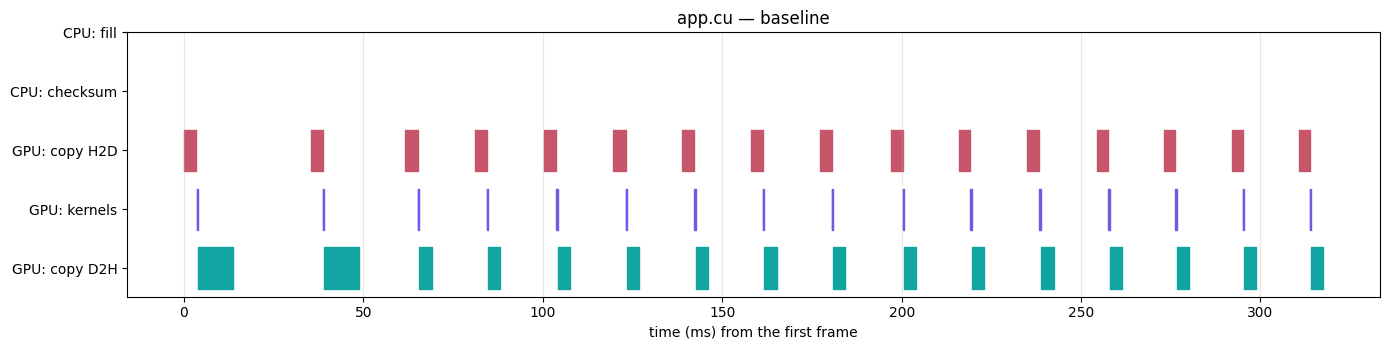

,busy time (ms)
CPU: fill,0.00
CPU: checksum,0.00
GPU: copy H2D,52.71
GPU: kernels,6.54
GPU: copy D2H,66.70


In [12]:
base_busy = nsys_timeline("app_base.nsys-rep", "app.cu — baseline")
base_busy

**บันทึกผลและตอบคำถาม**

(ก) จากตาราง `nvtx_sum`, `cuda_api_sum` และ `cuda_gpu_mem_time_sum` ระบุ **สามอันดับแรก** ที่กินเวลามากที่สุดต่อเฟรม
พร้อมตัวเลข (ms) และระบุว่าเป็นงานของ CPU, การคัดลอก หรือ kernel

_ตอบ:_ สามอันดับแรกคือ CPU checksum (5.75 ms/เฟรม, CPU), CPU fill (5.49 ms/เฟรม, CPU) และ D2H (4.17 ms/เฟรม, คัดลอก)

(ข) kernel ทั้งสองตัวรวมกันคิดเป็นกี่ % ของเวลาทั้งโปรแกรม ถ้าท่านทำให้ kernel เร็วขึ้น 10 เท่า
โปรแกรมทั้งหมดจะเร็วขึ้นประมาณกี่เท่า (ใช้กฎของ Amdahl จากสัปดาห์ที่ 2 แสดงวิธีคิด)

_ตอบ:_ kernel รวม 6.54 ms จาก 336.72 ms หรือ 1.94% ถ้าเร็วขึ้น 10 เท่า โปรแกรมเร็วขึ้น `1/(1-0.0194+0.0194/10) = 1.018` เท่า

(ค) บน timeline ช่วงที่ GPU ว่าง (ไม่มีแถบ GPU ใดเลย) เกิดขึ้นตอนไหน และ CPU กำลังทำอะไรอยู่ในช่วงนั้น

_ตอบ:_ GPU ว่างช่วงที่ CPU เติมข้อมูลและคำนวณ checksum รวมถึงช่วงจัดการบัฟเฟอร์ เห็นได้จากแถบ NVTX ที่คั่นระหว่างงาน GPU

**2.2 แก้ที่ต้นเหตุ — `app_fixed.cu`**

ใช้สิ่งที่เรียนในสัปดาห์ที่ 5 แก้สามเรื่อง โดย **ไม่แตะ kernel เลย**

| TODO | สิ่งที่ต้องแก้ | ต้นเหตุที่เห็นใน profile |
|---|---|---|
| (1) | host buffer เป็น pinned memory (`cudaMallocHost`) | memcpy pageable ช้าและบล็อก CPU |
| (2) | จอง device buffer ครั้งเดียวนอกลูป | cudaMalloc/cudaFree 32 ครั้ง (cudaFree ยัง sync ทั้งอุปกรณ์ด้วย) |
| (3)(4) | ใช้ 3 stream + `cudaMemcpyAsync` และรอเฉพาะ stream ที่ต้องใช้บัฟเฟอร์ | CPU กับ GPU ไม่เคยทำงานพร้อมกัน |

โครงสร้างใช้บัฟเฟอร์ 3 ช่อง (slot) หมุนเวียนกัน: ระหว่างที่ GPU ประมวลผลเฟรม f ในช่องหนึ่ง
CPU เตรียมเฟรมถัดไปในอีกช่องได้ทันที ผล `checksum` ต้อง **เท่ากับ `app` ทุกหลัก**

In [13]:
%%writefile app_fixed.cu
/* app_fixed.cu — เวอร์ชันที่ท่านต้องแก้ ผลลัพธ์ (checksum) ต้องเท่ากับ app.cu ทุกหลัก
   เติม TODO (1)–(4) โครงของลูปและ kernel ให้มาแล้ว */
#include <cstdio>
#include <cstdlib>
#include <chrono>
#include <nvtx3/nvToolsExt.h>

#define CUDA_CHECK(call)                                        \
  do {                                                          \
    cudaError_t err = (call);                                   \
    if (err != cudaSuccess) {                                   \
      fprintf(stderr, "CUDA %s:%d: %s\n", __FILE__, __LINE__,   \
              cudaGetErrorString(err));                         \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

const int FRAMES = 16;
const int NPIX   = 1 << 22;
const int NS     = 3;                        /* จำนวน stream = จำนวนช่อง (slot) ของบัฟเฟอร์ */

__global__ void normalize(int n, const float *in, float *out, float mean, float inv) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < n) out[i] = (in[i] - mean) * inv;
}
__global__ void gammaClamp(int n, float *x, float g) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < n) x[i] = powf(fminf(fmaxf(x[i], 0.0f), 1.0f), g);
}

static void fillFrame(float *h, int f) {
    for (int i = 0; i < NPIX; i++) h[i] = (float)((i * 7 + f * 13) % 1000);
}
static double checksum(const float *h) {
    double s = 0.0;
    for (int i = 0; i < NPIX; i++) s += h[i];
    return s;
}

int main() {
    size_t bytes = (size_t)NPIX * sizeof(float);
    double sums[FRAMES];

    nvtxRangePushA("init");
    CUDA_CHECK(cudaFree(0));

    float *h_in[NS], *h_out[NS], *d_in[NS], *d_out[NS];
    cudaStream_t st[NS];
    for (int s = 0; s < NS; s++) {
        /* TODO (1): จอง h_in[s] และ h_out[s] เป็น pinned memory (ไม่ใช่ malloc) */
        CUDA_CHECK(cudaMallocHost((void**)&h_in[s], bytes));
        CUDA_CHECK(cudaMallocHost((void**)&h_out[s], bytes));

        /* TODO (2): จอง d_in[s] และ d_out[s] ครั้งเดียวตรงนี้ — ห้ามจองในลูปเฟรม */
        CUDA_CHECK(cudaMalloc(&d_in[s], bytes));
        CUDA_CHECK(cudaMalloc(&d_out[s], bytes));

        CUDA_CHECK(cudaStreamCreate(&st[s]));
    }
    nvtxRangePop();

    auto t0 = std::chrono::steady_clock::now();
    for (int f = 0; f < FRAMES; f++) {
        int s = f % NS;
        nvtxRangePushA("frame");

        /* TODO (3): ก่อนใช้บัฟเฟอร์ช่อง s ซ้ำ ต้องรอให้งานเก่าของช่องนี้เสร็จ
           ให้รอเฉพาะ stream st[s] เท่านั้น — ห้ามใช้ cudaDeviceSynchronize()  */
        CUDA_CHECK(cudaStreamSynchronize(st[s]));

        if (f >= NS) {
            nvtxRangePushA("cpu: checksum");
            sums[f - NS] = checksum(h_out[s]);
            nvtxRangePop();
        }

        nvtxRangePushA("cpu: fill");
        fillFrame(h_in[s], f);
        nvtxRangePop();

        /* TODO (4a): คัดลอก h_in[s] -> d_in[s] แบบ async บน stream st[s] */
        CUDA_CHECK(cudaMemcpyAsync(d_in[s], h_in[s], bytes, cudaMemcpyHostToDevice, st[s]));

        normalize <<<(NPIX + 255) / 256, 256, 0, st[s]>>>(NPIX, d_in[s], d_out[s],
                                                          500.0f, 1.0f / 1000.0f);
        gammaClamp<<<(NPIX + 255) / 256, 256, 0, st[s]>>>(NPIX, d_out[s], 1.0f / 2.2f);
        CUDA_CHECK(cudaGetLastError());
        /* TODO (4b): คัดลอก d_out[s] -> h_out[s] แบบ async บน stream st[s] */
        CUDA_CHECK(cudaMemcpyAsync(h_out[s], d_out[s], bytes, cudaMemcpyDeviceToHost, st[s]));


        nvtxRangePop();
    }
    /* เก็บผลของ NS เฟรมสุดท้าย */
    for (int f = (FRAMES > NS ? FRAMES - NS : 0); f < FRAMES; f++) {
        int s = f % NS;
        CUDA_CHECK(cudaStreamSynchronize(st[s]));
        sums[f] = checksum(h_out[s]);
    }
    auto t1 = std::chrono::steady_clock::now();

    double total = 0.0;
    for (int f = 0; f < FRAMES; f++) total += sums[f];
    double ms = std::chrono::duration<double, std::milli>(t1 - t0).count();
    printf("app_fixed : %d เฟรม  %8.1f ms  (%.2f ms/เฟรม)  checksum = %.6e\n",
           FRAMES, ms, ms / FRAMES, total);

    for (int s = 0; s < NS; s++) {
        CUDA_CHECK(cudaFreeHost(h_in[s])); CUDA_CHECK(cudaFreeHost(h_out[s]));
        CUDA_CHECK(cudaFree(d_in[s]));     CUDA_CHECK(cudaFree(d_out[s]));
        CUDA_CHECK(cudaStreamDestroy(st[s]));
    }
    return 0;
}

Writing app_fixed.cu


In [14]:
!nvcc -O3 -arch={ARCH} app_fixed.cu -o app_fixed && ./app && ./app_fixed
!nsys profile -t cuda,nvtx,osrt -s none --cpuctxsw=none -o app_fixed -f true ./app_fixed
!nsys stats -q -r nvtx_sum,cuda_api_sum,cuda_gpu_mem_time_sum --force-export true app_fixed.nsys-rep

app       : 16 เฟรม     424.8 ms  (26.55 ms/เฟรม)  checksum = 1.680892e+07
app_fixed : 16 เฟรม     170.2 ms  (10.64 ms/เฟรม)  checksum = 1.680892e+07
app_fixed : 16 เฟรม     173.9 ms  (10.87 ms/เฟรม)  checksum = 1.680892e+07
Generating '/tmp/nsys-report-84bd.qdstrm'
[1/1] [========================100%] app_fixed.nsys-rep
Generated:
	/content/app_fixed.nsys-rep

 ** NVTX Range Summary (nvtx_sum):

 Time (%)  Total Time (ns)  Instances    Avg (ns)       Med (ns)      Min (ns)     Max (ns)    StdDev (ns)   Style       Range     
 --------  ---------------  ---------  -------------  -------------  -----------  -----------  -----------  -------  --------------
     63.5      539,590,270          1  539,590,270.0  539,590,270.0  539,590,270  539,590,270          0.0  PushPop  :init         
     18.4      156,586,880         16    9,786,680.0   10,517,953.0    4,596,542   12,900,507  2,293,323.3  PushPop  :frame        
      9.3       78,813,789         16    4,925,861.8    4,840,281.5    4

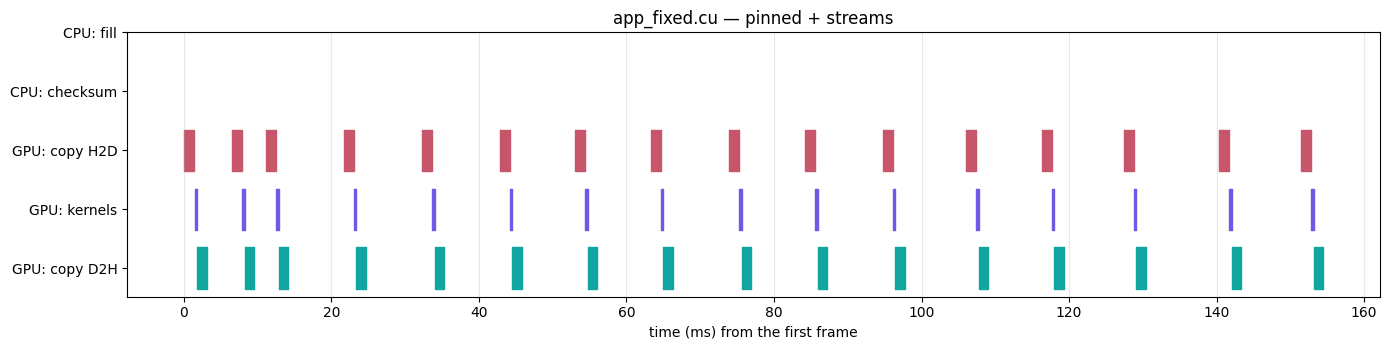

,baseline,fixed
CPU: fill,0.00,0.00
CPU: checksum,0.00,0.00
GPU: copy H2D,52.71,21.85
GPU: kernels,6.54,4.96
GPU: copy D2H,66.70,20.42


In [15]:
fixed_busy = nsys_timeline("app_fixed.nsys-rep", "app_fixed.cu — pinned + streams")
import pandas as pd
pd.DataFrame({"baseline": base_busy, "fixed": fixed_busy})

**บันทึกผลและตอบคำถาม**

(ง) เวลาต่อเฟรมลดจากเท่าใดเป็นเท่าใด (speedup กี่เท่า) และ checksum ตรงกันหรือไม่

_ตอบ:_ จากผล profile เวลาลดจาก 21.05 เป็น 10.87 ms/เฟรม หรือเร็วขึ้น 1.94 เท่า และ checksum เท่ากันที่ 1.680892e+07

(จ) ดู timeline ของ `app_fixed` — **คอขวดใหม่** คืออะไร ถ้าต้องการให้เร็วขึ้นอีก ท่านจะย้ายงานส่วนใดไปไว้บน GPU
และจะใช้ไลบรารีตัวใดช่วย (คำใบ้: checksum คือการ *reduce*)

_ตอบ:_ งาน CPU โดยเฉพาะ checksum ยังใช้ราว 5.78 ms ต่อครั้ง ฉันจะใช้ CUB reduce บน GPU แล้วคัดลอกกลับมาแค่ผลรวมหนึ่งค่า

---
### ส่วนที่ 3 — Nsight Compute: หาหลักฐานให้สิ่งที่รู้อยู่แล้ว

`kernels.cu` รวม kernel 5 ตัวที่ท่านเขียนหรือวัดมาแล้วใน Lab 3–4 แต่ละตัวถูกเรียกครั้งเดียว
ncu จะ **replay** แต่ละ kernel หลายรอบเพื่ออ่าน hardware counter ทีละกลุ่ม (จึงช้ากว่าการรันปกติมาก)

| ตัวชี้วัด (คอลัมน์ในตาราง) | อ่านอย่างไร |
|---|---|
| `Compute SOL %`, `Memory SOL %` | ใช้งานหน่วยคำนวณ / ระบบหน่วยความจำ ไปกี่ % ของเพดาน — ตัวที่สูงกว่าบอกว่า kernel ติดอะไร |
| `DRAM %` | แบนด์วิดท์ของ DRAM (HBM/GDDR) ที่ใช้จริง |
| `occ. achieved %` / `occ. theoretical %` | occupancy ที่วัดได้จริง / เพดานจาก launch config |
| `sectors / request` | global load ของหนึ่ง warp ต้องแตะกี่ sector (32 ไบต์) · อ่าน `float` เรียงกันครบ warp = **4** · กระจายสุด = **32** |
| `smem wavefronts / ld` | shared-memory load หนึ่งคำสั่งต้องแยกให้บริการกี่รอบ · ไม่มี bank conflict = **1** · 32-way = **32** |
| `smem ld conflicts` | จำนวน bank conflict ของ shared load ที่ ncu นับได้ |

In [16]:
%%writefile kernels.cu
/* kernels.cu — kernel ที่ท่านรู้จักแล้วจาก Lab 3–4 รวมไว้ในไฟล์เดียวเพื่อส่งให้ Nsight Compute
   แต่ละ kernel ถูกเรียกเพียงครั้งเดียว (ncu จะ replay ซ้ำเองหลายรอบเพื่อเก็บ counter)        */
#include <cstdio>
#include <cstdlib>

#define CUDA_CHECK(call)                                        \
  do {                                                          \
    cudaError_t err = (call);                                   \
    if (err != cudaSuccess) {                                   \
      fprintf(stderr, "CUDA %s:%d: %s\n", __FILE__, __LINE__,   \
              cudaGetErrorString(err));                         \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

#define T 32
#define TILE 32
#define ROWS 8

/* Lab 3: naive matmul (block 16x16) */
__global__ void matmulNaive(int N, const float *A, const float *B, float *C) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    if (row < N && col < N) {
        float sum = 0.0f;
        for (int k = 0; k < N; k++) sum += A[row*N + k] * B[k*N + col];
        C[row*N + col] = sum;
    }
}

/* Lab 4 ส่วนที่ 2 (ก): tiled T = 32 */
__global__ void tiled32(int N, const float *A, const float *B, float *C) {
    __shared__ float As[T][T], Bs[T][T];
    int tx = threadIdx.x, ty = threadIdx.y;
    int row = blockIdx.y*T + ty, col = blockIdx.x*T + tx;
    float sum = 0.0f;
    for (int t = 0; t < N/T; t++) {
        As[ty][tx] = A[row*N + (t*T + tx)];
        Bs[ty][tx] = B[(t*T + ty)*N + col];
        __syncthreads();
        for (int k = 0; k < T; k++) sum += As[ty][k] * Bs[k][tx];
        __syncthreads();
    }
    C[row*N + col] = sum;
}

/* Lab 4 ส่วนที่ 2 (ข): tiled T = 32 สลับแกน */
__global__ void tiled32Swapped(int N, const float *A, const float *B, float *C) {
    __shared__ float As[T][T], Bs[T][T];
    int tx = threadIdx.x, ty = threadIdx.y;
    int row = blockIdx.y*T + tx;
    int col = blockIdx.x*T + ty;
    float sum = 0.0f;
    for (int t = 0; t < N/T; t++) {
        As[tx][ty] = A[row*N + (t*T + ty)];
        Bs[tx][ty] = B[(t*T + tx)*N + col];
        __syncthreads();
        for (int k = 0; k < T; k++) sum += As[tx][k] * Bs[k][ty];
        __syncthreads();
    }
    C[row*N + col] = sum;
}

/* Lab 4 ส่วนที่ 3: transpose ไทล์ [32][32] และ [32][33] */
__global__ void transposeTile(int N, const float *in, float *out) {
    __shared__ float tile[TILE][TILE];
    int x = blockIdx.x*TILE + threadIdx.x;
    int y = blockIdx.y*TILE + threadIdx.y;
    for (int j = 0; j < TILE; j += ROWS)
        tile[threadIdx.y + j][threadIdx.x] = in[(y+j)*N + x];
    __syncthreads();
    x = blockIdx.y*TILE + threadIdx.x;
    y = blockIdx.x*TILE + threadIdx.y;
    for (int j = 0; j < TILE; j += ROWS)
        out[(y+j)*N + x] = tile[threadIdx.x][threadIdx.y + j];
}
__global__ void transposeTilePad(int N, const float *in, float *out) {
    __shared__ float tile[TILE][TILE + 1];
    int x = blockIdx.x*TILE + threadIdx.x;
    int y = blockIdx.y*TILE + threadIdx.y;
    for (int j = 0; j < TILE; j += ROWS)
        tile[threadIdx.y + j][threadIdx.x] = in[(y+j)*N + x];
    __syncthreads();
    x = blockIdx.y*TILE + threadIdx.x;
    y = blockIdx.x*TILE + threadIdx.y;
    for (int j = 0; j < TILE; j += ROWS)
        out[(y+j)*N + x] = tile[threadIdx.x][threadIdx.y + j];
}

int main(int argc, char **argv) {
    int N  = (argc > 1) ? atoi(argv[1]) : 1024;       /* matmul N x N    */
    int NT = (argc > 2) ? atoi(argv[2]) : 4096;       /* transpose NT x NT */
    size_t mb = (size_t)N * N * sizeof(float), tb = (size_t)NT * NT * sizeof(float);
    float *dA, *dB, *dC, *dI, *dO;
    CUDA_CHECK(cudaMalloc(&dA, mb)); CUDA_CHECK(cudaMalloc(&dB, mb));
    CUDA_CHECK(cudaMalloc(&dC, mb));
    CUDA_CHECK(cudaMalloc(&dI, tb)); CUDA_CHECK(cudaMalloc(&dO, tb));
    CUDA_CHECK(cudaMemset(dA, 0, mb)); CUDA_CHECK(cudaMemset(dB, 0, mb));
    CUDA_CHECK(cudaMemset(dI, 0, tb));

    matmulNaive     <<<dim3(N/16, N/16), dim3(16, 16)>>>(N, dA, dB, dC);
    tiled32         <<<dim3(N/T, N/T),   dim3(T, T)>>>  (N, dA, dB, dC);
    tiled32Swapped  <<<dim3(N/T, N/T),   dim3(T, T)>>>  (N, dA, dB, dC);
    transposeTile   <<<dim3(NT/TILE, NT/TILE), dim3(TILE, ROWS)>>>(NT, dI, dO);
    transposeTilePad<<<dim3(NT/TILE, NT/TILE), dim3(TILE, ROWS)>>>(NT, dI, dO);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaDeviceSynchronize());
    printf("kernels: รันครบ 5 kernel (matmul N = %d, transpose N = %d)\n", N, NT);

    CUDA_CHECK(cudaFree(dA)); CUDA_CHECK(cudaFree(dB)); CUDA_CHECK(cudaFree(dC));
    CUDA_CHECK(cudaFree(dI)); CUDA_CHECK(cudaFree(dO));
    return 0;
}

Writing kernels.cu


In [17]:
!nvcc -O3 -arch={ARCH} -lineinfo kernels.cu -o kernels
METRICS = "gpu__time_duration.sum,sm__throughput.avg.pct_of_peak_sustained_elapsed,gpu__compute_memory_throughput.avg.pct_of_peak_sustained_elapsed,dram__throughput.avg.pct_of_peak_sustained_elapsed,sm__warps_active.avg.pct_of_peak_sustained_active,sm__maximum_warps_per_active_cycle_pct,l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum,l1tex__t_requests_pipe_lsu_mem_global_op_ld.sum,l1tex__data_pipe_lsu_wavefronts_mem_shared_op_ld.sum,smsp__inst_executed_op_shared_ld.sum,l1tex__data_bank_conflicts_pipe_lsu_mem_shared_op_ld.sum,l1tex__t_sector_hit_rate.pct"
!ncu --csv --metrics {METRICS} ./kernels 1024 4096 > ncu_kernels.csv 2>&1
!grep -m3 -E "ERR_NVGPUCTRPERM|==ERROR==" ncu_kernels.csv || echo "ncu เก็บค่าได้ครบ"
ncu_summary("ncu_kernels.csv")

ncu เก็บค่าได้ครบ


,time (us),Compute SOL %,Memory SOL %,DRAM %,occ. achieved %,occ. theoretical %,sectors / request,smem wavefronts / ld,smem ld conflicts,L1 hit %
Kernel,,,,,,,,,,
matmulNaive,9182.72,62.51,62.51,6.44,98.68,100.0,2.0,NaN,0.0,87.38
tiled32,5254.69,75.18,75.18,9.36,99.94,100.0,4.0,1.2,0.0,0.00
tiled32Swapped,38026.62,10.39,49.17,1.76,99.83,100.0,32.0,7.2,234881024.0,87.64
transposeTile,1653.50,12.19,48.30,33.53,94.84,100.0,4.0,32.0,16252928.0,0.00
transposeTilePad,686.46,29.84,73.51,73.51,94.93,100.0,4.0,1.0,0.0,0.00


> ถ้าเห็น `ERR_NVGPUCTRPERM` แปลว่าเครื่องนี้ไม่อนุญาตให้อ่าน performance counter

**3.2 รายงานฉบับเต็มของ kernel เดียว** — `--set basic` ให้ Speed of Light, Launch Statistics และ Occupancy
พร้อมข้อความแนะนำ (บรรทัดที่ขึ้นต้นด้วย `OPT` หรือ `WRN`) ที่ ncu วิเคราะห์ให้เอง

In [18]:
!ncu --set basic -k matmulNaive ./kernels 1024 4096

==PROF== Connected to process 1990 (/content/kernels)
==PROF== Profiling "matmulNaive": 0%....50%....100% - 9 passes
kernels: รันครบ 5 kernel (matmul N = 1024, transpose N = 4096)
==PROF== Disconnected from process 1990
[1990] kernels@127.0.0.1
  matmulNaive(int, const float *, const float *, float *) (64, 64, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         5.00
    SM Frequency                    Mhz       585.00
    Elapsed Cycles                cycle    5,370,315
    Memory Throughput                 %        62.53
    DRAM Throughput                   %         6.56
    Duration                         ms         9.18
    L1/TEX Cache Throughput           %        93.81
    L2 Cache Throughput               %         6.75
    SM A

**บันทึกผลและตอบคำถาม**

(ก) คัดลอกตารางจาก `ncu_summary` มาวางใน **ตารางที่ 1 (ส่วน B)** ท้ายแลป

(ข) `matmulNaive` มี `sectors / request` เท่าใด ตัวเลขนี้บอกว่า naive matmul มีปัญหาเรื่อง coalescing หรือไม่
ถ้าไม่ใช่ ปัญหาจริงของมันคืออะไร (ย้อนดูสไลด์สัปดาห์ที่ 5 เรื่อง "count the loads")

_ตอบ:_ ได้ 2 sectors/request จึงไม่ใช่ปัญหา coalescing หลัก แต่แต่ละ thread อ่าน A และ B ซ้ำมาก เพราะไม่มี tile ช่วย reuse

(ค) เทียบ `tiled32` กับ `tiled32Swapped` ทุกคอลัมน์ — ใน Lab 4 เราอธิบายว่าเวอร์ชันสลับแกนช้าเพราะ
global memory ไม่ coalesced **ตาราง ncu ยืนยันคำอธิบายนั้นหรือไม่ และพบอะไรเพิ่ม**
ให้คำนวณ bank ของ `As[tx][k]` ด้วย `(tx*32 + k) % 32` สำหรับ tx = 0..31 ประกอบคำตอบ

_ตอบ:_ ตารางยืนยัน: sectors/request เพิ่มจาก 4 เป็น 32 และ shared wavefronts/load จาก 1.2 เป็น 7.2; shared conflicts เพิ่มจาก 0 เป็น 234,881,024 ครั้ง เพราะ `(tx*32+k)%32 = k` ทุก tx ชน bank เดียวกัน

(ง) `transposeTile` กับ `transposeTilePad` ต่างกันที่คอลัมน์ใด ตรงกับที่ท่านคำนวณใน Lab 4 ส่วนที่ 3 หรือไม่

_ตอบ:_ padding ลด shared wavefronts/load จาก 32 เป็น 1 และ conflicts จาก 16,252,928 เป็น 0; เวลาในรอบนี้ลดจาก 1653.50 เป็น 686.46 µs ตรงกับเหตุผลเรื่อง bank conflict ใน Lab 4

---
### ส่วนที่ 4 — ปรับแต่งด้วยหลักฐาน: ค่าเฉลี่ยรายแถว (row mean)

`rowmean.cu` คำนวณค่าเฉลี่ยของแต่ละแถวในเมทริกซ์ 16,384 × 1,024 (64 MB) เวอร์ชัน `v0` ใช้ **หนึ่งเธรดต่อหนึ่งแถว**
และ block ขนาด 32 — ดูสมเหตุสมผล แต่ยังไม่มีใคร profile มันเลย

ทำตามลำดับนี้ **ทีละขั้น** และบันทึกทุกขั้นลงใน **ตารางที่ 2 (บันทึกการปรับแต่ง)**

1. วัดเวลา v0 และ cuBLAS (เวอร์ชันอ้างอิง)
2. profile v0 ด้วย ncu → อ่านว่าคอขวดคืออะไร → เขียนสมมติฐาน **ก่อน** แก้โค้ด
3. เขียน v1 (หนึ่ง warp ต่อหนึ่งแถว) ตาม TODO → ตรวจ `[ผ่าน]` → วัดซ้ำ → profile ซ้ำ
4. ตัดสินใจว่าจะหยุดหรือไปต่อ โดยอ้างตัวเลข `DRAM %`

In [19]:
%%writefile rowmean.cu
/* rowmean.cu — ค่าเฉลี่ยรายแถวของเมทริกซ์ M x N (row-major)
   out[r] = (x[r][0] + x[r][1] + ... + x[r][N-1]) / N                        */
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <cublas_v2.h>

#define CUDA_CHECK(call)                                        \
  do {                                                          \
    cudaError_t err = (call);                                   \
    if (err != cudaSuccess) {                                   \
      fprintf(stderr, "CUDA %s:%d: %s\n", __FILE__, __LINE__,   \
              cudaGetErrorString(err));                         \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

#define CUBLAS_CHECK(call)                                      \
  do {                                                          \
    cublasStatus_t st = (call);                                 \
    if (st != CUBLAS_STATUS_SUCCESS) {                          \
      fprintf(stderr, "cuBLAS %s:%d: status %d\n",              \
              __FILE__, __LINE__, (int)st);                     \
      exit(EXIT_FAILURE);                                       \
    }                                                           \
  } while (0)

const int M = 16384;                  /* จำนวนแถว   */
const int N = 1024;                   /* จำนวนคอลัมน์ (หารด้วย 128 ลงตัว) */

/* ---- v0: โค้ดตั้งต้น (ห้ามแก้) — หนึ่งเธรดต่อหนึ่งแถว ------------------- */
__global__ void rowMeanV0(int M, int N, const float *x, float *out) {
    int r = blockIdx.x * blockDim.x + threadIdx.x;
    if (r < M) {
        float s = 0.0f;
        for (int c = 0; c < N; c++) s += x[(size_t)r * N + c];
        out[r] = s / N;
    }
}
static void launchV0(const float *x, float *out) {
    rowMeanV0<<<(M + 31) / 32, 32>>>(M, N, x, out);
}

/* ---- v1: หนึ่ง warp ต่อหนึ่งแถว (ส่วนที่ต้องเขียนเอง) ------------------ */
__global__ void rowMeanV1(int M, int N, const float *x, float *out) {
    int warp = (blockIdx.x * blockDim.x + threadIdx.x) / 32;   /* = หมายเลขแถว */
    int lane = threadIdx.x % 32;
    if (warp >= M) return;                    /* ทั้ง warp ออกพร้อมกัน ไม่ divergent */

    const float *row = x + (size_t)warp * N;
    float s = 0.0f;
    /* TODO (1): วนอ่านทั้งแถวโดยให้ lane ที่ติดกันอ่านคอลัมน์ที่ติดกัน
       lane 0 อ่าน c = 0, 32, 64, ... · lane 1 อ่าน c = 1, 33, 65, ... แล้วสะสมใน s */
    for (int c = lane; c < N; c += 32) s += row[c];

    /* TODO (2): รวม s ของทั้ง 32 lane ด้วย __shfl_down_sync (offset 16, 8, 4, 2, 1) */
    for (int offset = 16; offset > 0; offset /= 2)
        s += __shfl_down_sync(0xffffffff, s, offset);

    /* TODO (3): lane 0 เขียนค่าเฉลี่ยของแถวลง out[warp] */
    if (lane == 0) out[warp] = s / N;

}
static void launchV1(const float *x, float *out) {
    /* TODO (4): เลือกจำนวนเธรดต่อ block แล้วคำนวณจำนวน block ให้ได้ M warp พอดี
       (หนึ่ง warp = หนึ่งแถว)                                                     */
    const int threads = 256;                 /* TODO (4) */
    const int blocks  = (M * 32 + threads - 1) / threads; /* TODO (4) */
    rowMeanV1<<<blocks, threads>>>(M, N, x, out);
}

/* ---- v2 (โบนัส ไม่บังคับ): v1 + โหลดทีละ float4 ---------------------------
   ถ้าไม่ทำโบนัส ให้แก้ launchV2 ด้านล่างให้เรียก launchV1 แทน (ค่าเริ่มต้น)          */
__global__ void rowMeanV2(int M, int N, const float *x, float *out) {
    int warp = (blockIdx.x * blockDim.x + threadIdx.x) / 32;
    int lane = threadIdx.x % 32;
    if (warp >= M) return;
    const float4 *row = reinterpret_cast<const float4*>(x + (size_t)warp * N);
    float s = 0.0f;
    /* โบนัส: เหมือน v1 แต่แต่ละ lane อ่าน float4 (16 ไบต์) ต่อครั้ง
       แถวหนึ่งมี N/4 ตัว float4                                              */
    for (int c = lane; c < N / 4; c += 32) {
        float4 v = row[c];
        s += v.x + v.y + v.z + v.w;
    }
    for (int offset = 16; offset > 0; offset /= 2)
        s += __shfl_down_sync(0xffffffff, s, offset);
    if (lane == 0) out[warp] = s / N;
}
static void launchV2(const float *x, float *out) {
    rowMeanV2<<<(M * 32 + 255) / 256, 256>>>(M, N, x, out); /* โบนัส: เปลี่ยนเป็น rowMeanV2<<<...>>> เมื่อเขียน v2 เสร็จ */
}

/* ---- อ้างอิงจากไลบรารี: cuBLAS SGEMV  out = (1/N) * X * ones ---------- */
static cublasHandle_t g_handle;
static float *g_ones;
static void launchCublas(const float *x, float *out) {
    const float alpha = 1.0f / N, beta = 0.0f;
    /* x (row-major M x N) ในมุมมอง column-major คือ X^T ขนาด N x M, lda = N
       ต้องการ X * ones = (X^T)^T * ones  ->  CUBLAS_OP_T                     */
    CUBLAS_CHECK(cublasSgemv(g_handle, CUBLAS_OP_T, N, M, &alpha,
                             x, N, g_ones, 1, &beta, out, 1));
}

static float timeIt(void (*launch)(const float*, float*), const float *dx, float *dout) {
    cudaEvent_t s, e; float ms = 0.0f;
    CUDA_CHECK(cudaEventCreate(&s)); CUDA_CHECK(cudaEventCreate(&e));
    launch(dx, dout);                                  /* warm-up */
    CUDA_CHECK(cudaEventRecord(s));
    for (int r = 0; r < 20; r++) launch(dx, dout);
    CUDA_CHECK(cudaEventRecord(e));
    CUDA_CHECK(cudaEventSynchronize(e));
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaEventElapsedTime(&ms, s, e));
    CUDA_CHECK(cudaEventDestroy(s)); CUDA_CHECK(cudaEventDestroy(e));
    return ms / 20.0f;
}

int main(int argc, char **argv) {
    /* ./rowmean        -> จับเวลาทุกเวอร์ชัน
       ./rowmean 0|1|2  -> รันเวอร์ชันเดียวครั้งเดียว (ใช้กับ ncu)             */
    int only = (argc > 1) ? atoi(argv[1]) : -1;
    size_t bytes = (size_t)M * N * sizeof(float);
    float *hx = (float*)malloc(bytes), *hout = (float*)malloc(M * sizeof(float));
    double *ref = (double*)malloc(M * sizeof(double));
    for (int r = 0; r < M; r++) {
        double s = 0.0;
        for (int c = 0; c < N; c++) {
            float v = (float)((r * 7 + c * 13) % 101) * 0.01f;
            hx[(size_t)r * N + c] = v;
            s += v;
        }
        ref[r] = s / N;
    }
    float *dx, *dout;
    CUDA_CHECK(cudaMalloc(&dx, bytes)); CUDA_CHECK(cudaMalloc(&dout, M * sizeof(float)));
    CUDA_CHECK(cudaMemcpy(dx, hx, bytes, cudaMemcpyHostToDevice));

    void (*launch[3])(const float*, float*) = {launchV0, launchV1, launchV2};
    if (only >= 0 && only <= 2) {
        launch[only](dx, dout);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaDeviceSynchronize());
        printf("rowmean: รัน v%d หนึ่งครั้ง\n", only);
        return 0;
    }

    CUBLAS_CHECK(cublasCreate(&g_handle));
    CUDA_CHECK(cudaMalloc(&g_ones, N * sizeof(float)));
    {
        float *h1 = (float*)malloc(N * sizeof(float));
        for (int c = 0; c < N; c++) h1[c] = 1.0f;
        CUDA_CHECK(cudaMemcpy(g_ones, h1, N * sizeof(float), cudaMemcpyHostToDevice));
        free(h1);
    }

    const char *name[4] = {"v0  thread/row, block 32 ", "v1  warp/row, block 256  ",
                           "v2  warp/row + float4    ", "cuBLAS SGEMV (อ้างอิง)   "};
    void (*all[4])(const float*, float*) = {launchV0, launchV1, launchV2, launchCublas};
    float t0 = 0.0f;
    printf("M = %d แถว  N = %d คอลัมน์  (%.0f MB)\n", M, N, bytes / 1e6);
    for (int w = 0; w < 4; w++) {
        CUDA_CHECK(cudaMemset(dout, 0, M * sizeof(float)));
        float ms = timeIt(all[w], dx, dout);
        if (w == 0) t0 = ms;
        CUDA_CHECK(cudaMemcpy(hout, dout, M * sizeof(float), cudaMemcpyDeviceToHost));
        double maxerr = 0.0;
        for (int r = 0; r < M; r++) maxerr = fmax(maxerr, fabs(hout[r] - ref[r]));
        printf("  %s : %7.3f ms   %6.1f GB/s   speedup %5.2fx   %s\n",
               name[w], ms, bytes / 1e9 / (ms / 1e3), t0 / ms,
               (maxerr < 1e-3) ? "[ผ่าน]" : "[ไม่ผ่าน]");
    }

    CUBLAS_CHECK(cublasDestroy(g_handle));
    CUDA_CHECK(cudaFree(g_ones)); CUDA_CHECK(cudaFree(dx)); CUDA_CHECK(cudaFree(dout));
    free(hx); free(hout); free(ref);
    return 0;
}

Writing rowmean.cu


In [20]:
!nvcc -O3 -arch={ARCH} -lineinfo rowmean.cu -lcublas -o rowmean && ./rowmean

M = 16384 แถว  N = 1024 คอลัมน์  (67 MB)
  v0  thread/row, block 32  :   1.491 ms     45.0 GB/s   speedup  1.00x   [ผ่าน]
  v1  warp/row, block 256   :   0.254 ms    263.8 GB/s   speedup  5.86x   [ผ่าน]
  v2  warp/row + float4     :   0.255 ms    263.4 GB/s   speedup  5.85x   [ผ่าน]
  cuBLAS SGEMV (อ้างอิง)    :   0.270 ms    248.4 GB/s   speedup  5.52x   [ผ่าน]


**4.1 Profile v0** — ส่ง `0` เป็นอาร์กิวเมนต์เพื่อให้รันเฉพาะ v0 หนึ่งครั้ง

In [21]:
!ncu --section SpeedOfLight --section Occupancy --section LaunchStats --section MemoryWorkloadAnalysis -k rowMeanV0 ./rowmean 0
!ncu --csv --metrics {METRICS} ./rowmean 0 > ncu_rowmean_v0.csv 2>&1
ncu_summary("ncu_rowmean_v0.csv")

==PROF== Connected to process 2100 (/content/rowmean)
==PROF== Profiling "rowMeanV0": 0%....50%....100% - 9 passes
rowmean: รัน v0 หนึ่งครั้ง
==PROF== Disconnected from process 2100
[2100] rowmean@127.0.0.1
  rowMeanV0(int, int, const float *, float *) (512, 1, 1)x(32, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.99
    SM Frequency                    Mhz       584.97
    Elapsed Cycles                cycle      872,777
    Memory Throughput                 %        48.10
    DRAM Throughput                   %        28.77
    Duration                         ms         1.49
    L1/TEX Cache Throughput           %        96.19
    L2 Cache Throughput               %         5.73
    SM Active Cycles              cycle   846,554.45
    Co

,time (us),Compute SOL %,Memory SOL %,DRAM %,occ. achieved %,occ. theoretical %,sectors / request,smem ld conflicts,L1 hit %
Kernel,,,,,,,,,
rowMeanV0,1491.97,3.01,48.11,28.45,27.78,50.0,32.0,0.0,86.45


**สมมติฐานของท่าน (เขียนก่อนแก้โค้ด)** — ตัวชี้วัดใดผิดปกติ บอกอะไร และท่านจะแก้อย่างไร

_ตอบ:_ v0 มี 32 sectors/request, occupancy 27.78% และ DRAM 28.45% เพราะแต่ละ thread อ่านทีละแถว ฉันจะให้หนึ่ง warp อ่านแถวเดียวกันแล้วรวมด้วย shuffle เพื่อให้โหลดต่อเนื่องขึ้น

**4.2 เขียน v1** — กลับไปแก้ TODO (1)–(4) ในเซลล์ `rowmean.cu` ด้านบน แล้วรันเซลล์ถัดไป

In [22]:
!nvcc -O3 -arch={ARCH} -lineinfo rowmean.cu -lcublas -o rowmean && ./rowmean
!ncu --csv --metrics {METRICS} ./rowmean 1 > ncu_rowmean_v1.csv 2>&1
pd.concat([ncu_summary("ncu_rowmean_v0.csv"), ncu_summary("ncu_rowmean_v1.csv")])

M = 16384 แถว  N = 1024 คอลัมน์  (67 MB)
  v0  thread/row, block 32  :   0.978 ms     68.6 GB/s   speedup  1.00x   [ผ่าน]
  v1  warp/row, block 256   :   0.253 ms    265.0 GB/s   speedup  3.86x   [ผ่าน]
  v2  warp/row + float4     :   0.254 ms    264.6 GB/s   speedup  3.86x   [ผ่าน]
  cuBLAS SGEMV (อ้างอิง)    :   0.267 ms    251.0 GB/s   speedup  3.66x   [ผ่าน]


,time (us),Compute SOL %,Memory SOL %,DRAM %,occ. achieved %,occ. theoretical %,sectors / request,smem ld conflicts,L1 hit %
Kernel,,,,,,,,,
rowMeanV0,1491.97,3.01,48.11,28.45,27.78,50.0,32.0,0.0,86.45
rowMeanV1,260.45,21.30,92.65,92.65,91.48,100.0,4.0,0.0,0.68


**บันทึกผลและตอบคำถาม**

(ก) v1 เร็วกว่า v0 กี่เท่า และทำได้กี่ GB/s เทียบกับ cuBLAS SGEMV แล้วเป็นอย่างไร

_ตอบ:_ รอบวัดแรก v1 เร็วกว่า v0 5.86 เท่า ได้ 263.8 GB/s ส่วน cuBLAS ได้ 248.4 GB/s จึงเร็วกว่านิดหน่อย

(ข) หลังได้ v1 ท่านจะ **หยุด** หรือ **ไปต่อ** ให้ตัดสินจาก `DRAM %` และเวลาต่ำสุดเชิงทฤษฎี
(ขนาดข้อมูล ÷ แบนด์วิดท์ที่วัดได้ใน Lab 2) แสดงวิธีคิด

_ตอบ:_ ฉันจะหยุด: 64 MiB ÷ 241 GB/s ≈ 0.278 ms ใกล้เวลา v1 ที่ 0.254 ms และ profiler วัด DRAM ได้ 92.65% ตัวเลขเวลาอาจต่างจากค่าประมาณเพราะเงื่อนไขการวัดและ cache

(ค) *(โบนัส +5 ไม่เกินคะแนนเต็ม)* เขียน v2 ที่โหลดทีละ `float4` แล้วรายงานว่าได้ผลเพิ่มกี่ % และเพราะอะไรจึงได้น้อย

_ตอบ:_ v2 ไม่เร็วขึ้น: 0.255 เทียบกับ v1 0.254 ms ช้าลงราว 0.4% เพราะ v1 อ่านต่อเนื่องอยู่แล้ว และ float4 ยังอ่านข้อมูลเท่าเดิม

### ตารางที่ 2 — บันทึกการปรับแต่ง (เติมทุกช่อง)

| ขั้น | เวอร์ชัน | หลักฐานจาก profiler (ชื่อตัวชี้วัด = ค่า) | สมมติฐาน / สิ่งที่แก้ | เวลา (ms) | GB/s | ผ่าน? |
|---|---|---|---|---|---|---|
| 0 | v0 | sectors/request = 32; DRAM = 28.45%; occ. = 27.78% | — (baseline) | 1.491 | 45.0 | ผ่าน |
| 1 | v1 | sectors/request = 4; DRAM = 92.65%; occ. = 91.48% | หนึ่ง warp ต่อแถว + shuffle | 0.254 | 263.8 | ผ่าน |
| ref | cuBLAS SGEMV | — | ไลบรารีอ้างอิง | 0.270 | 248.4 | ผ่าน |

### ตารางที่ 1 — สรุปผลการวัด (เติมให้ครบทุกช่อง)

**A. เวลาและ throughput**

| # | โปรแกรม / kernel | ขนาด | เวลา | TFLOPS หรือ GB/s | เทียบกับ |
|---|---|---|---|---|---|
| 1 | tiled32 | N = 2048 | 28.074 ms | 0.612 TFLOPS | 1.00× |
| 2 | cuBLAS SGEMM | N = 2048 | 2.429 ms | 7.074 TFLOPS | 11.56× เทียบแถว 1 |
| 3 | CuPy `a @ b` (events) | N = 2048 | 3.576 ms | 4.804 TFLOPS | 7.85× เทียบแถว 1 |
| 4 | app (baseline) | 16 เฟรม | 21.05 ms/เฟรม | — | 1.00× |
| 5 | app_fixed | 16 เฟรม | 10.87 ms/เฟรม | — | 1.94× เทียบแถว 4 |

**B. ค่าจาก Nsight Compute (`ncu_summary("ncu_kernels.csv")`)**

| kernel | time (µs) | Compute SOL % | Memory SOL % | DRAM % | occ. achieved % | sectors / request | smem wavefronts / ld |
|---|---|---|---|---|---|---|---|
| matmulNaive | 9182.72 | 62.51 | 62.51 | 6.44 | 98.68 | 2.0 | — |
| tiled32 | 5254.69 | 75.18 | 75.18 | 9.36 | 99.94 | 4.0 | 1.2 |
| tiled32Swapped | 38026.62 | 10.39 | 49.17 | 1.76 | 99.83 | 32.0 | 7.2 |
| transposeTile | 1653.50 | 12.19 | 48.30 | 33.53 | 94.84 | 4.0 | 32.0 |
| transposeTilePad | 686.46 | 29.84 | 73.51 | 73.51 | 94.93 | 4.0 | 1.0 |

---
## 4. คำถามวิเคราะห์

**Q1.** ใช้ตัวเลขจาก `nsys stats` ของ `app` (ส่วนที่ 2) คำนวณว่าถ้าท่านมีเวลาปรับได้เพียง **หนึ่ง** อย่างในสามอย่างนี้
— (ก) kernel เร็วขึ้น 10 เท่า (ข) การคัดลอกเร็วขึ้น 3 เท่า (ค) งาน CPU (fill + checksum) หายไปทั้งหมด —
แต่ละทางเลือกได้ speedup ทั้งโปรแกรมเท่าใด (แสดงวิธีคิดด้วยกฎของ Amdahl)

_ตอบ:_ ใช้เวลา frame 336.72 ms: kernel 6.54 ms (`f_k=0.0194`), copy 119.41 ms (`f_copy=0.3546`), CPU fill+checksum 179.94 ms (`f_cpu=0.5344`)
(ก) `1/(1-0.0194+0.0194/10) = 1.018` เท่า (ข) `1/(1-0.3546+0.3546/3) = 1.31` เท่า (ค) `1/(1-0.5344) = 2.15` เท่า เลือกปรับงาน CPU

**Q2.** ให้เหตุผลสองข้อว่าทำไม cuBLAS จึงเร็วกว่า `tiled32` แล้วยกตัวอย่าง **หนึ่ง** กรณีจากแลปนี้
ที่การเขียน kernel เองน่าจะดีกว่าการเรียกไลบรารีหลายตัวต่อกัน (คำใบ้: `normalize` + `gammaClamp`) ประหยัดการอ่าน-เขียน
DRAM ได้กี่ไบต์ต่อเฟรม

_ตอบ:_ cuBLAS reuse ข้อมูลใน tile ได้ดีกว่าและปรับ kernel ให้เหมาะกับ GPU ส่วนการรวม normalize กับ gammaClamp จะลดการเขียนแล้วอ่านค่ากลาง 32 MiB ต่อเฟรม

**Q3.** (ต่อจากส่วนที่ 3 ข้อ ค) ออกแบบการทดลองหนึ่งการทดลองที่แยกได้ว่าความช้าของ `tiled32Swapped`
มาจาก uncoalesced global load กี่ส่วน และจาก bank conflict กี่ส่วน — แก้อะไร วัดอะไร คาดว่าจะเห็นอะไร

_ตอบ:_ ฉันจะวัด swapped เดิม เทียบกับรุ่นแก้เฉพาะ global load และรุ่นแก้เฉพาะ shared memory โดยคงงานคำนวณเดิม แล้วดูเวลา, sectors/request และ shared conflicts; คาดว่าแต่ละรุ่นลดตัวชี้วัดของปัญหาที่แก้

**Q4.** Nsight Systems กับ Nsight Compute ตอบคำถามต่างกันอย่างไร ในแลปนี้ถ้าท่านเริ่มจาก ncu กับ `app.cu`
แทน nsys ท่านจะเสียเวลาไปกับอะไร

_ตอบ:_ Nsight Systems ดูเวลาทั้งโปรแกรม ส่วน Nsight Compute ดู counter ของแต่ละ kernel ถ้าเริ่มจาก ncu จะเสียเวลาเจาะ kernel ก่อนเห็นว่าคอขวดอยู่ที่ CPU หรือ memcpy

**Q5.** `rowMeanV0` มี occupancy ต่ำ ถ้าเพื่อนเสนอให้แก้แค่ block size จาก 32 เป็น 256 (ยังเป็นหนึ่งเธรดต่อแถว)
อธิบายว่า (ก) theoretical occupancy จะเปลี่ยนเป็นเท่าใด (ข) ทำไมจึงน่าจะช่วยได้น้อยเมื่อเทียบกับ v1
ให้อ้างตัวชี้วัดจาก ncu ที่ท่านวัดได้

_ตอบ:_ บน T4 block 32 มี theoretical occupancy 50%; block 256 คาดเป็น 100% แต่ยังมี 32 sectors/request และอ่านแถวละ 1024 ค่าแบบ serial จึงช่วยน้อยกว่า v1 ที่ลดเหลือ 4 sectors/request และได้ DRAM 92.65%


---
## 5. การเตรียมไฟล์ส่งงาน

รันเซลล์ถัดไปเพื่อบีบไฟล์ `.cu` และ `.csv` ทั้งหมดแล้วดาวน์โหลด จากนั้นอัปโหลดพร้อมโน้ตบุ๊กนี้ผ่าน LMS
(ไม่ต้องส่งไฟล์ `.nsys-rep` เพราะมีขนาดใหญ่)

> **ก่อนรัน** แก้ `sid` ในเซลล์ถัดไปให้เป็นรหัสนักศึกษาของท่าน
> ชื่อไฟล์ที่ผิดจะทำให้ระบบตรวจงานหาไฟล์ไม่เจอ

In [23]:
import os
sid = "6730614023"        # TODO: แก้เป็นรหัสนักศึกษาของท่าน
!zip -q Lab5_{sid}.zip *.cu ncu_*.csv
print("ไฟล์ที่บีบแล้ว:", os.path.getsize(f"Lab5_{sid}.zip"), "bytes")
try:
    from google.colab import files
    files.download(f"Lab5_{sid}.zip")
except Exception as e:
    print("ดาวน์โหลดเองจากแถบไฟล์ด้านซ้าย:", e)

ไฟล์ที่บีบแล้ว: 13372 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 6. รายการสิ่งที่ต้องส่ง

- [x] โน้ตบุ๊ก `Lab5_<รหัสนักศึกษา>.ipynb` รันครบทุกเซลล์พร้อม output (รวมกราฟ timeline ทั้งสองรูป)
- [x] ไฟล์ `gemm_lib.cu`, `app.cu`, `app_fixed.cu`, `kernels.cu`, `rowmean.cu` และ `ncu_*.csv` (บีบรวมเป็น .zip)
- [x] cuBLAS และ `rowMeanV1` ขึ้น `[ผ่าน]` · checksum ของ `app_fixed` เท่ากับ `app` ทุกหลัก
- [x] ตารางที่ 1 (A และ B) และตารางที่ 2 ครบทุกช่อง พร้อมหน่วย
- [x] คำตอบของส่วนที่ 1 (ก)–(ค) · ส่วนที่ 2 (ก)–(จ) · ส่วนที่ 3 (ข)–(ง) · ส่วนที่ 4 สมมติฐาน และ (ก)–(ข)
- [x] คำตอบคำถามวิเคราะห์ Q1–Q5

## 7. เกณฑ์การให้คะแนน

| องค์ประกอบ | คะแนน | เกณฑ์การพิจารณา |
|---|---|---|
| ความถูกต้อง | 20 | cuBLAS `[ผ่าน]` 5 · `app_fixed` checksum ตรง 7 · `rowMeanV1` `[ผ่าน]` 8 |
| หลักฐานจาก profiler | 30 | nsys ก่อน/หลัง 10 · ตาราง ncu ส่วนที่ 3 10 · ncu ของ v0/v1 พร้อมสมมติฐาน 10 |
| ผลการปรับแต่ง | 25 | `app_fixed` เร็วขึ้นพร้อมเหตุผล 8 · v1 เร็วขึ้น ≥ 4 เท่า 10 · ตารางที่ 2 ครบ 7 |
| คำถามวิเคราะห์ | 25 | Q1–Q5 ข้อละ 5 ต้องแสดงวิธีคิดและอ้างตัวเลขของตนเอง |
| **รวม** | **100** | |

**หักคะแนนเพิ่มเติม** รายงานเวลาของโปรแกรมที่ยัง `[ไม่ผ่าน]` หรือ checksum ไม่ตรง หักข้อละ 5 คะแนน ·
อ้าง "ncu บอกว่า..." โดยไม่ระบุชื่อตัวชี้วัดและค่า หักครั้งละ 2 คะแนน